<a href="https://colab.research.google.com/github/nhjung-phd/TimeSeriesAnalysis/blob/main/notebooks/ATE_ATT_ATU_Colab_Example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ATE · ATT · ATU — AI adoption and productivity

**목적:** 같은 가상기업 자료에서 ATE, ATT, ATU를 계산하고, **관측자료만으로는 잠재결과를 모두 알 수 없다는 문제**를 이해합니다.

- 교육용 합성자료이며 실제 연구결과가 아닙니다.
- 그래프 제목·축·범례는 모두 영어로 출력합니다.
- 위 데이터의 `Y0`와 `Y1`은 **교육용 시뮬레이션이어서 둘 다 알고 있는 값**입니다. 현실에서는 한 기업의 두 잠재결과를 동시에 관측할 수 없습니다.

## 1. 잠재결과와 추정 대상\n\n기업 $i$가 AI를 도입했을 때 잠재 생산성은 $Y_i(1)$, 도입하지 않았을 때는 $Y_i(0)$. 개별 처치효과는 $\tau_i=Y_i(1)-Y_i(0)$.

$$ATE=E[Y(1)-Y(0)]$$
$$ATT=E[Y(1)-Y(0)\mid D=1]$$
$$ATU=E[Y(1)-Y(0)\mid D=0]$$

$D=1$: AI 도입기업, $D=0$: 미도입기업.

중요: $ATE=P(D=1)ATT+P(D=0)ATU$. **ATT와 ATU가 다르면 기업별 처치효과가 이질적**입니다.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family":"DejaVu Sans",
    "figure.figsize":(10,4.5),
    "axes.grid":True,
    "grid.alpha":0.25,
    "axes.spines.top":False,
    "axes.spines.right":False,
})
print("DATA_KIND: SYNTHETIC — educational potential-outcomes example")

DATA_KIND: SYNTHETIC — educational potential-outcomes example


## 2. 8개 기업의 가상 잠재결과

AI 도입 여부를 일부러 기업의 생산성 수준과 연관되게 설정했습니다. 이 때문에 두 집단의 **관측 평균 차이**를 인과효과로 오해하면 안 됩니다.

In [8]:
firms = ["A","B","C","D","E","F","G","H"]
D = np.array([1,1,1,1,0,0,0,0])
Y0 = np.array([100,110,90,120,75,85,95,105], dtype=float)
tau = np.array([12,10,8,6,2,4,6,8], dtype=float)
Y1 = Y0 + tau
Y_observed = np.where(D == 1, Y1, Y0)
df = pd.DataFrame({"Firm":firms,"AI_adopted":D,"Y0_counterfactual":Y0,
                   "Y1_if_adopted":Y1,"True_effect":tau,"Observed_outcome":Y_observed})
print(df.to_string(index=False))

Firm  AI_adopted  Y0_counterfactual  Y1_if_adopted  True_effect  Observed_outcome
   A           1              100.0          112.0         12.0             112.0
   B           1              110.0          120.0         10.0             120.0
   C           1               90.0           98.0          8.0              98.0
   D           1              120.0          126.0          6.0             126.0
   E           0               75.0           77.0          2.0              75.0
   F           0               85.0           89.0          4.0              85.0
   G           0               95.0          101.0          6.0              95.0
   H           0              105.0          113.0          8.0             105.0


## 3. ATE·ATT·ATU 손계산

처치집단 A~D의 효과: 12, 10, 8, 6 → **ATT = 9**.

미처치집단 E~H의 *가정상 도입했을 경우의* 효과: 2, 4, 6, 8 → **ATU = 5**.

전체 평균 **ATE = 7**, 도입 비율 0.5이므로 $0.5	imes9+0.5	imes5=7$.

In [9]:
ATT = df.loc[df.AI_adopted == 1, "True_effect"].mean()
ATU = df.loc[df.AI_adopted == 0, "True_effect"].mean()
ATE = df["True_effect"].mean()
p = df.AI_adopted.mean()
print(f"ATT = {ATT:.1f}, ATU = {ATU:.1f}, ATE = {ATE:.1f}")
print(f"Weighted identity: {p:.2f} x {ATT:.1f} + {1-p:.2f} x {ATU:.1f} = {p*ATT + (1-p)*ATU:.1f}")
assert np.isclose(ATE, p*ATT+(1-p)*ATU)

ATT = 9.0, ATU = 5.0, ATE = 7.0
Weighted identity: 0.50 x 9.0 + 0.50 x 5.0 = 7.0


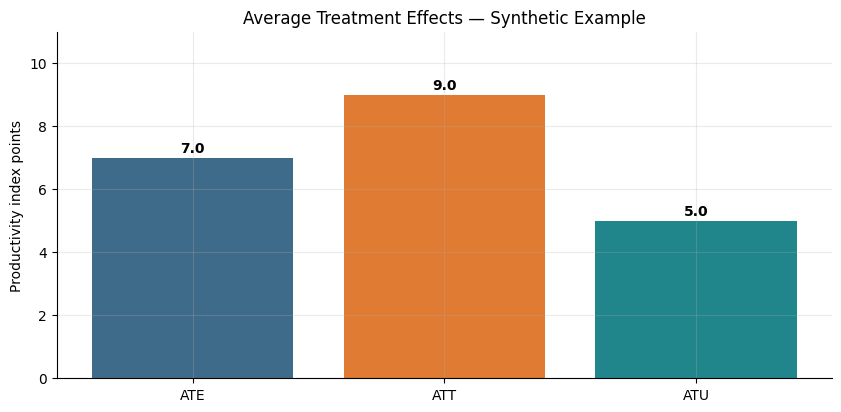

In [10]:
fig, ax = plt.subplots()
ax.bar(["ATE", "ATT", "ATU"], [ATE, ATT, ATU], color=["#3f6b8a","#df7b33","#21868c"])
ax.set_title("Average Treatment Effects — Synthetic Example")
ax.set_ylabel("Productivity index points")
for x, y in enumerate([ATE, ATT, ATU]): ax.text(x, y+0.18, f"{y:.1f}", ha="center", weight="bold")
ax.set_ylim(0, 11)
plt.show()

## 4. 왜 단순한 관측 평균 차이와 ATE는 다를까?

관측된 결과만 사용하면 도입기업 평균 114, 미도입기업 평균 90으로 차이는 **24**입니다. 그러나 시뮬레이션에서 알고 있는 전체 ATE는 **7**입니다.

두 집단은 정책이 없을 때의 잠재결과 $Y(0)$부터 다르므로, **관측 평균 차이 24를 정책효과라고 해석할 수 없습니다.**

Observed treated mean = 114.0
Observed untreated mean = 90.0
Naive difference = 24.0; true ATE = 7.0


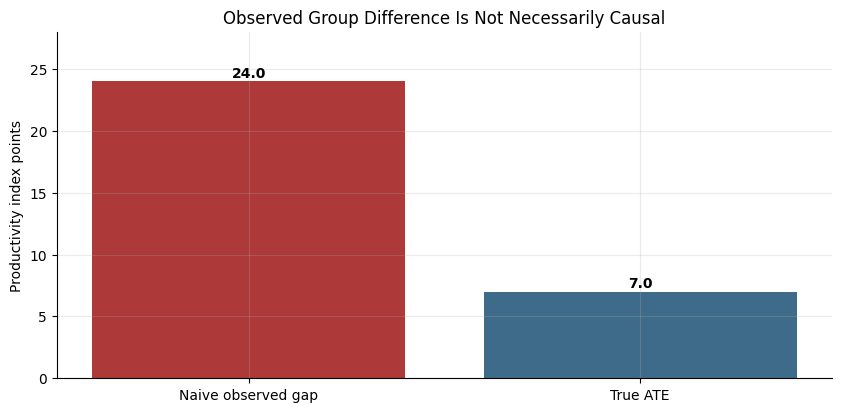

In [11]:
mean_treated = df.loc[df.AI_adopted==1,"Observed_outcome"].mean()
mean_control = df.loc[df.AI_adopted==0,"Observed_outcome"].mean()
naive = mean_treated - mean_control
print(f"Observed treated mean = {mean_treated:.1f}")
print(f"Observed untreated mean = {mean_control:.1f}")
print(f"Naive difference = {naive:.1f}; true ATE = {ATE:.1f}")
fig, ax = plt.subplots()
ax.bar(["Naive observed gap", "True ATE"], [naive, ATE], color=["#ad3939","#3f6b8a"])
ax.set_title("Observed Group Difference Is Not Necessarily Causal")
ax.set_ylabel("Productivity index points")
for i,v in enumerate([naive,ATE]): ax.text(i,v+0.35,f"{v:.1f}",ha="center",weight="bold")
ax.set_ylim(0,28)
plt.show()

## 5. 현실 자료에서는 무엇이 관측되는가?

- 도입기업에서는 $Y(1)$만 관측되고 $Y(0)$은 관측할 수 없습니다.
- 미도입기업에서는 $Y(0)$만 관측되고 $Y(1)$은 관측할 수 없습니다.
- 따라서 지금까지 계산한 ATE, ATT, ATU는 **시뮬레이션에서 정답을 아는 특별한 경우**입니다.

현실에서 추정하려면 무작위배정, 조건부 교환가능성·중첩성, DID 평행추세, 기타 연구설계별 식별가정과 자료가 필요합니다. ATT나 ATE를 추정했다고 ATU까지 자동으로 식별되는 것은 아닙니다.

In [12]:
observed_table = df[["Firm","AI_adopted","Observed_outcome"]].copy()
observed_table["Missing_counterfactual"] = np.where(df.AI_adopted==1,"Y(0)","Y(1)")
print(observed_table.to_string(index=False))

Firm  AI_adopted  Observed_outcome Missing_counterfactual
   A           1             112.0                   Y(0)
   B           1             120.0                   Y(0)
   C           1              98.0                   Y(0)
   D           1             126.0                   Y(0)
   E           0              75.0                   Y(1)
   F           0              85.0                   Y(1)
   G           0              95.0                   Y(1)
   H           0             105.0                   Y(1)


## 6. 강의 토론

1. AI를 이미 도입한 기업의 효과를 알고 싶다면 ATE·ATT·ATU 중 무엇이 맞을까요?
2. 아직 도입하지 않은 기업에 AI를 확대한다면 무엇을 추정해야 할까요?
3. 도입 여부가 원래의 생산성 수준과 관련되면 단순 집단 평균 차이는 왜 잘못될까요?
4. 관측자료에서 $Y(0)$ 또는 $Y(1)$을 추정하려면 어떤 가정과 비교집단이 필요할까요?

**정리:** ATT는 도입기업의 효과, ATU는 미도입기업이 도입했을 경우의 효과, ATE는 대상 모집단 전체 평균효과입니다. 단순 관측 평균 차이와 구별해야 합니다.